<h3>ЗАГРУЗКА ДАТАСЕТА<h3>  "Safety Helmet Detection" 
<br><a>https://www.kaggle.com/datasets/andrewmvd/hard-hat-detection<a>

In [1]:
import os
import glob
import xml.etree.ElementTree as ET
from collections import Counter
import kagglehub
from ultralytics import YOLO

/home/user/Shcheglov/Shcheglov/Helmets_and_masks/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

# Download latest version
path = kagglehub.dataset_download("andrewmvd/hard-hat-detection")

print("Path to dataset files:", path)

Path to dataset files: /home/user/.cache/kagglehub/datasets/andrewmvd/hard-hat-detection/versions/1


In [3]:
import os
import glob
import xml.etree.ElementTree as ET
from collections import Counter

def extract_labels_from_xml(xml_dir):
    """
    Извлекает уникальные метки классов из XML-файлов формата Pascal VOC
    и подсчитывает количество упоминаний каждой метки.
    """
    labels = set()
    labels_count = Counter()
    
    # Находим все XML-файлы в указанной директории
    xml_files = glob.glob(os.path.join(xml_dir, '*.xml'))
    
    if not xml_files:
        print(f"Ошибка: не найдено XML файлов по пути: {xml_dir}")
        return [], {}

    for xml_file in xml_files:
        try:
            # Парсинг XML файла
            tree = ET.parse(xml_file)
            root = tree.getroot()
            
            # Ищем все объекты (bounding boxes) внутри аннотации
            for obj in root.findall('object'):
                name_tag = obj.find('name')
                if name_tag is not None and name_tag.text:
                    label = name_tag.text.strip()
                    labels.add(label)
                    labels_count[label] += 1
                    
        except Exception as e:
            print(f"Ошибка при парсинге файла {xml_file}: {e}")
            
    # Возвращаем отсортированный список уникальных меток и словарь с их количеством
    return sorted(list(labels)), labels_count


if __name__ == "__main__":
    # =====================================================================
    # ВАЖНО: Укажите путь к папке с XML-файлами (обычно это папка 'annotations')
    # =====================================================================
    
    # Если вы скачали датасет к себе на компьютер:
    xml_directory = '/home/user/.cache/kagglehub/datasets/andrewmvd/hard-hat-detection/versions/1/annotations' 
    
    # Если вы работаете в Kaggle Notebook, путь будет выглядеть так:
    # xml_directory = '/kaggle/input/hard-hat-detection/annotations'
    
    unique_labels, counts = extract_labels_from_xml(xml_directory)
    
    print("Найденные уникальные метки (классы):")
    print("-" * 40)
    for label in unique_labels:
        print(f" • {label: <15} (встречается {counts[label]:>5} раз)")
    print("-" * 40)
    print(f"Всего уникальных классов: {len(unique_labels)}")

Найденные уникальные метки (классы):
----------------------------------------
 • head            (встречается  5785 раз)
 • helmet          (встречается 18966 раз)
 • person          (встречается   751 раз)
----------------------------------------
Всего уникальных классов: 3


СОБЕРЕМ ДАТАСЕТ ДЛЯ ОБУЧЕНИЯ . ДЛЯ ЭТОГО КОНВЕРТИРУЕМ ДАННЫЕ ИЗ ФОРМАТА <b>PASCAL_VOC В <b>YOLO И СОЗДАДИМ ПРАВИЛЬНУЮ СТРУКТУРУ ПАПОК

И СОЗДАДИМ НОВЫЙ КЛАСС - Head_with_helmet, на основе объединения bbox класса head и класса helmet. Класс head выкенем, больше он нам не нужен

In [ ]:
import os
import glob
import xml.etree.ElementTree as ET
import shutil
import random
import yaml

def convert_bbox_voc_to_yolo(size, box):
    """Конвертация Pascal VOC в YOLO формат."""
    dw = 1.0 / size[0]
    dh = 1.0 / size[1]
    x_center = (box[0] + box[2]) / 2.0
    y_center = (box[1] + box[3]) / 2.0
    w = box[2] - box[0]
    h = box[3] - box[1]

    x_center *= dw
    w *= dw
    y_center *= dh
    h *= dh
    
    x_center = max(0.0, min(1.0, x_center))
    y_center = max(0.0, min(1.0, y_center))
    w = max(0.0, min(1.0, w))
    h = max(0.0, min(1.0, h))
    
    return (x_center, y_center, w, h)

def _inter_area(a, b):
    """Площадь пересечения двух боксов (xmin, ymin, xmax, ymax)."""
    xA, yA = max(a[0], b[0]), max(a[1], b[1])
    xB, yB = min(a[2], b[2]), min(a[3], b[3])
    return max(0.0, xB - xA) * max(0.0, yB - yA)

def _union_boxes(a, b):
    """Объединение двух боксов."""
    return (min(a[0], b[0]), min(a[1], b[1]), max(a[2], b[2]), max(a[3], b[3]))

def create_yolo_dataset(root_dir, output_dir, val_ratio=0.2, seed=42):
    annotations_dir = os.path.join(root_dir, 'annotations')
    images_dir = os.path.join(root_dir, 'images')
    
    if not os.path.exists(images_dir):
        images_dir = root_dir

    for split in ['train', 'val']:
        os.makedirs(os.path.join(output_dir, 'images', split), exist_ok=True)
        os.makedirs(os.path.join(output_dir, 'labels', split), exist_ok=True)

    # Жестко задаем наши два класса
    classes = ['head_with_helmet', 'helmet']
    class_mapping = {name: idx for idx, name in enumerate(classes)}
    print(f"✅ Определены классы ({len(classes)}): {class_mapping}")

    xml_files = glob.glob(os.path.join(annotations_dir, '*.xml'))
    random.seed(seed)
    random.shuffle(xml_files)
    
    split_idx = int(len(xml_files) * (1 - val_ratio))
    datasets_map = {
        'train': xml_files[:split_idx],
        'val': xml_files[split_idx:]
    }

    stats = {'train': 0, 'val': 0, 'missing': 0, 'created_helmet_on_head': 0, 'kept_helmet_alone': 0}
    
    for split, xmls in datasets_map.items():
        for xml_file in xmls:
            base_name = os.path.splitext(os.path.basename(xml_file))[0]
            
            img_path = None
            for ext in ['.jpg', '.png', '.jpeg']:
                potential_path = os.path.join(images_dir, base_name + ext)
                if os.path.exists(potential_path):
                    img_path = potential_path
                    break
            
            if not img_path:
                stats['missing'] += 1
                continue

            shutil.copy(img_path, os.path.join(output_dir, 'images', split, os.path.basename(img_path)))

            try:
                tree = ET.parse(xml_file)
                root = tree.getroot()
                
                size = root.find('size')
                img_w = int(size.find('width').text)
                img_h = int(size.find('height').text)
                
                raw_objects = []
                for obj in root.findall('object'):
                    cls_name = obj.find('name').text.strip()
                    # Нам нужны только helmet и head для создания объединений
                    if cls_name not in ['helmet', 'head']:
                        continue
                    
                    bndbox = obj.find('bndbox')
                    xmin = float(bndbox.find('xmin').text)
                    ymin = float(bndbox.find('ymin').text)
                    xmax = float(bndbox.find('xmax').text)
                    ymax = float(bndbox.find('ymax').text)
                    
                    raw_objects.append({
                        'cls': cls_name,
                        'box': (xmin, ymin, xmax, ymax)
                    })

                txt_lines = []
                
                heads = [o['box'] for o in raw_objects if o['cls'] == 'head']
                helmets = [o['box'] for o in raw_objects if o['cls'] == 'helmet']
                
                used_helmets = set()

                # 1. Ищем каски на головах
                for i, h_box in enumerate(helmets):
                    is_on_head = False
                    for hd_box in heads:
                        inter = _inter_area(h_box, hd_box)
                        # Если каска пересекается с головой хотя бы на 10% её площади
                        if inter > 0 and inter > (_inter_area(h_box, h_box) * 0.1):
                            is_on_head = True
                            union_box = _union_boxes(h_box, hd_box)
                            yolo_bbox = convert_bbox_voc_to_yolo((img_w, img_h), union_box)
                            
                            txt_lines.append(f"{class_mapping['head_with_helmet']} {yolo_bbox[0]:.6f} {yolo_bbox[1]:.6f} {yolo_bbox[2]:.6f} {yolo_bbox[3]:.6f}")
                            stats['created_helmet_on_head'] += 1
                            break # Одна каска - одна голова
                    
                    if is_on_head:
                        used_helmets.add(i)

                # 2. Оставшиеся каски (не на голове) добавляем как helmet
                for i, h_box in enumerate(helmets):
                    if i not in used_helmets:
                        yolo_bbox = convert_bbox_voc_to_yolo((img_w, img_h), h_box)
                        txt_lines.append(f"{class_mapping['helmet']} {yolo_bbox[0]:.6f} {yolo_bbox[1]:.6f} {yolo_bbox[2]:.6f} {yolo_bbox[3]:.6f}")
                        stats['kept_helmet_alone'] += 1

                # Класс 'head' (головы без касок) просто игнорируется!

                # Записываем только если есть хотя бы один объект (иначе это фон)
                if txt_lines:
                    txt_filename = base_name + '.txt'
                    with open(os.path.join(output_dir, 'labels', split, txt_filename), 'w') as f:
                        f.write('\n'.join(txt_lines))
                    
                stats[split] += 1
                    
            except Exception as e:
                print(f"⚠️ Ошибка при парсинге {xml_file}: {e}")

    abs_output_dir = os.path.abspath(output_dir)
    data_yaml = {
        'path': abs_output_dir,
        'train': 'images/train',
        'val': 'images/val',
        'nc': len(classes),
        'names': classes
    }
    
    with open(os.path.join(output_dir, 'dataset.yaml'), 'w') as f:
        yaml.dump(data_yaml, f, sort_keys=False, allow_unicode=True)
        
    print(f"\n🎉 Датасет успешно собран!")
    print(f"📂 Путь: {abs_output_dir}")
    print(f"🖼️ Train: {stats['train']} изображений")
    print(f"🔍 Val:   {stats['val']} изображений")
    print(f"🆕 Касок на голове (head_with_helmet): {stats['created_helmet_on_head']}")
    print(f"🪖 Касок отдельно (helmet): {stats['kept_helmet_alone']}")
    if stats['missing'] > 0:
        print(f"❗ Пропущено (нет картинки): {stats['missing']} XML-файлов")

if __name__ == "__main__":
    ROOT_DIR = '/home/user/.cache/kagglehub/datasets/andrewmvd/hard-hat-detection/versions/1'
    OUTPUT_DIR = './hard_hat_dataset_v4'
    
    create_yolo_dataset(ROOT_DIR, OUTPUT_DIR, val_ratio=0.2)

Найдено 5000 XML файлов.
✅ Определены классы (3): {'head': 0, 'helmet': 1, 'person': 2}

🎉 Датасет успешно собран!
📂 Путь: /home/user/Shcheglov/Shcheglov/Helmets_and_masks/hard_hat_dataset
🖼️ Train: 4000 изображений
🔍 Val:   1000 изображений


ОБУЧЕНИЕ YOLO26n

In [1]:
from ultralytics import YOLO

YAML_PATH = "/home/user/Shcheglov/Shcheglov/Helmets_and_masks/hard_hat_dataset/dataset.yaml"
YOLO26_BASE_PATH = "/home/user/Shcheglov/Shcheglov/Helmets_and_masks/yolo26n.pt"
# 1. Загружаем предобученную модель (nano версия для быстрого старта)
model = YOLO(YOLO26_BASE_PATH) 

# 2. Запускаем обучение
results = model.train(
    data=YAML_PATH,
    epochs=100,        # Количество эпох
    imgsz=640,        # Размер входного изображения
    batch=32,         # Размер батча (уменьшите, если не хватает видеопамяти)
    device='0',       # '0' для GPU, 'cpu' для процессора
    name='hard_hat_yolov26n'
)

New https://pypi.org/project/ultralytics/8.4.174 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.173 🚀 Python-3.12.11 torch-2.6.0+cu124 CUDA:0 (NVIDIA A100 80GB PCIe, 81038MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/user/Shcheglov/Shcheglov/Helmets_and_masks/hard_hat_dataset/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4,

ПРОБЛЕМА ПОСЛЕ ОБУЧЕНИЯ: F1 для класса person порядка 0.03-0.04  при confidence < 0.3
<img src="/home/user/Shcheglov/Shcheglov/Helmets_and_masks/runs/detect/hard_hat_yolov26n/BoxF1_curve.png" alt="Логотип" width="900" height="500">

ДИАГНОСТИКА ДАТАСЕТА ПО КЛАССАМ

In [5]:
from collections import Counter
import glob

for split in ['train', 'val']:
    box_cnt, img_cnt = Counter(), Counter()
    for f in glob.glob(f'hard_hat_dataset/labels/{split}/*.txt'):
        present = set()
        for line in open(f):
            p = line.split()
            cid, w, h = int(p[0]), float(p[3]), float(p[4])
            box_cnt[cid] += 1
            present.add(cid)
            if cid == 2 and (w < 0.05 or h < 0.05):
                box_cnt['person_degenerate'] += 1   # признак битых/обрезанных боксов
        for c in present:
            img_cnt[c] += 1
    print(split, 'боксов:', dict(box_cnt), '| изображений с классом:', dict(img_cnt))

train боксов: {1: 15207, 0: 4621, 2: 633, 'person_degenerate': 48} | изображений с классом: {1: 3666, 0: 728, 2: 126}
val боксов: {0: 1164, 1: 3759, 2: 118, 'person_degenerate': 3} | изображений с классом: {0: 192, 1: 915, 2: 32}


УБИРАЕМ КЛАСС PERSON (ДИСБАЛАНС, БИТЫЕ МЕТКИ). YOLO26n УЖЕ УМЕЕТ ИЗ КОРОБКИ ДЕТЕКТИРОВАТЬ КЛАСС PERSON

In [6]:
import glob
import os
import yaml

DATASET_DIR = '/home/user/Shcheglov/Shcheglov/Helmets_and_masks/hard_hat_dataset'   # папка с images/ и labels/
PERSON_ID = '2'                    # id класса person в текущей разметке
REMOVE_EMPTIED = True              # удалять кадры, оставшиеся без объектов
splits = ['train', 'val']

# --- Шаг 0. Удаляем дубликаты, созданные оверсэмплингом person (если запускали) ---
for split in splits:
    for pattern in (f'{DATASET_DIR}/labels/{split}/*_dup*.txt',
                    f'{DATASET_DIR}/images/{split}/*_dup*.*'):
        for p in glob.glob(pattern):
            os.remove(p)
print('Дубликаты оверсэмплинга удалены (если были).')

# --- Шаг 1. Фильтруем строки person из всех label-файлов ---
for split in splits:
    lbl_dir = f'{DATASET_DIR}/labels/{split}'
    img_dir = f'{DATASET_DIR}/images/{split}'
    removed = emptied = deleted = 0

    for f in glob.glob(lbl_dir + '/*.txt'):
        with open(f) as fh:
            lines = [l.strip() for l in fh if l.strip()]

        kept = [l for l in lines if l.split()[0] != PERSON_ID]
        removed += len(lines) - len(kept)

        with open(f, 'w') as fh:
            fh.write('\n'.join(kept))

        # Опустевшим считаем только файл, где объекты БЫЛИ, но все оказались person.
        # Истинно пустые (фоновые) файлы оставляем как негативные примеры.
        if lines and not kept:
            emptied += 1
            if REMOVE_EMPTIED:
                base = os.path.splitext(os.path.basename(f))[0]
                os.remove(f)
                for e in ('.png', '.jpg', '.jpeg'):
                    p = os.path.join(img_dir, base + e)
                    if os.path.exists(p):
                        os.remove(p)
                        deleted += 1
                        break

    print(f'{split}: удалено боксов person={removed}, '
          f'опустевших файлов={emptied}, удалено пар image+label={deleted}')

# --- Шаг 2. Обновляем dataset.yaml ---
yaml_path = f'{DATASET_DIR}/dataset.yaml'
with open(yaml_path) as f:
    data = yaml.safe_load(f)

data['nc'] = 2
data['names'] = ['head', 'helmet']

with open(yaml_path, 'w') as f:
    yaml.dump(data, f, sort_keys=False, allow_unicode=True)
print('dataset.yaml обновлён:', data)

Дубликаты оверсэмплинга удалены (если были).
train: удалено боксов person=633, опустевших файлов=0, удалено пар image+label=0
val: удалено боксов person=118, опустевших файлов=0, удалено пар image+label=0
dataset.yaml обновлён: {'path': '/home/user/Shcheglov/Shcheglov/Helmets_and_masks/hard_hat_dataset', 'train': 'images/train', 'val': 'images/val', 'nc': 2, 'names': ['head', 'helmet']}


In [7]:
from collections import Counter
import glob

for split in ['train', 'val']:
    cnt = Counter()
    for f in glob.glob(f'hard_hat_dataset/labels/{split}/*.txt'):
        for l in open(f):
            if l.strip():
                cnt[int(l.split()[0])] += 1
    print(split, dict(cnt))   # ожидаем только ключи 0 и 1

train {1: 15207, 0: 4621}
val {0: 1164, 1: 3759}


ОБУЧАЕМ ЗАНОВО УЖЕ БЕЗ КЛАССА PERSON 

In [8]:
from ultralytics import YOLO

YAML_PATH = "/home/user/Shcheglov/Shcheglov/Helmets_and_masks/hard_hat_dataset/dataset.yaml"
YOLO26_BASE_PATH = "/home/user/Shcheglov/Shcheglov/Helmets_and_masks/yolo26n.pt"
# 1. Загружаем предобученную модель (nano версия для быстрого старта)
model = YOLO(YOLO26_BASE_PATH) 

# 2. Запускаем обучение
results = model.train(
    data=YAML_PATH,
    epochs=100,        # Количество эпох
    imgsz=640,        # Размер входного изображения
    batch=32,         # Размер батча (уменьшите, если не хватает видеопамяти)
    device='0',       # '0' для GPU, 'cpu' для процессора
    name='hard_hat_yolov26n_no_person'
)

New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.173 🚀 Python-3.12.11 torch-2.6.0+cu124 CUDA:0 (NVIDIA A100 80GB PCIe, 81038MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/user/Shcheglov/Shcheglov/Helmets_and_masks/hard_hat_dataset/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4,

ПРОБЛЕМА ПОСЛЕ ОБУЧЕНИЯ: СЛИШКОМ МНОГО ЛОЖНЫХ СРАБАТЫВАНИЙ! Модель детектит каску там где ее нет
<img src="/home/user/Shcheglov/Shcheglov/Helmets_and_masks/runs/detect/hard_hat_yolov26n_no_person/confusion_matrix_normalized.png" alt="Логотип" width="900" height="500">

Почему в train так много ложных срабатываний,хотя изображений в валидационной выборке - 1000 а в train - 4000. Потому что модель считает не картинки, а отдельные bbox

ПОДНИМЕМ КОНФИДЕНС ДО РАБОЧЕГО ПОРОГА (т.к встроенный валидатор прогоняет все после train с порогом в 0.001) из - за этого так много FP

In [9]:
model = YOLO('/home/user/Shcheglov/Shcheglov/Helmets_and_masks/runs/detect/hard_hat_yolov26n_no_person/weights/best.pt')
model.val(data='/home/user/Shcheglov/Shcheglov/Helmets_and_masks/hard_hat_dataset/dataset.yaml',
          conf=0.4,      # рабочий порог
          iou=0.5,
          save_dir='runs/val_operating5')

Ultralytics 8.4.173 🚀 Python-3.12.11 torch-2.14.1+cu130 CPU (Intel Xeon Gold 6346 CPU @ 3.10GHz)
YOLO26n summary (fused): 120 layers, 2,375,226 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1720.1±377.8 MB/s, size: 291.7 KB)
val: Scanning /home/user/Shcheglov/Shcheglov/Helmets_and_masks/hard_hat_dataset/labels/val.cache... 1000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 262.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 1.7it/s 36.2s0.5ss
                   all       1000       4923      0.937      0.889       0.88      0.586
                  head        192       1164      0.923      0.855      0.838      0.559
                helmet        915       3759      0.951      0.922      0.921      0.614
Speed: 2.1ms preprocess, 25.0ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /home/user/Shcheglov/Shcheglov/Helmets_and_masks/run

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f10837f7cb0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

ПРОВЕРКА МИНИМАЛЬНОГО РАЗМЕРА ДЕТЕКТИРУЕМОЙ КАСКИ(РАЗМЕР КАСКИ ПРИ КОТОРОМ НАЧИНАЕТ ПАДАТЬ RECALL) 

In [8]:
import math
from torchvision.ops import box_iou
import torch
import numpy as np

HELMET_ID, CONF, IOU_TH = 1,0.3,0.6

def parse_gt(path):
    gt = []
    with open(path) as f:
        for line in f:
            p = line.split()
            if not p or int(float(p[0])) != HELMET_ID:
                continue
            cls,xc,yc,w,h = map(float,p)
            gt.append(dict(size=math.sqrt(w*h),
                       box = (xc-w/2,yc-h/2,xc+w/2,yc+h/2),
                       hit = False))
    return gt


def inter_area(a, b):
    xA, yA = max(a[0], b[0]), max(a[1], b[1])
    xB, yB = min(a[2], b[2]), min(a[3], b[3])
    return max(0.0, xB - xA) * max(0.0, yB - yA)

def bbox_area(bbox):
    return (bbox[2] - bbox[0]) * (bbox[3] - bbox[1])

def iou(a, b):
    inter = inter_area(a, b)
    union = bbox_area(a) + bbox_area(b) - inter
    return inter / union if union > 0 else 0.0
    
model = YOLO('/home/user/Shcheglov/Shcheglov/Helmets_and_masks/runs/detect/hard_hat_yolov26n_no_person/weights/best.pt')
rows = [] #size,hit
for img in glob.glob("/home/user/Shcheglov/Shcheglov/Helmets_and_masks/hard_hat_dataset/images/val/*.*"):
    base = os.path.splitext(os.path.basename(img))[0]
    gt = parse_gt(f'/home/user/Shcheglov/Shcheglov/Helmets_and_masks/hard_hat_dataset/labels/val/{base}.txt')
    if not gt:
        continue
    r = model.predict(img,conf = CONF, verbose=False)[0]
    keep = (r.boxes.cls == HELMET_ID)
    pred_boxes = r.boxes.xyxyn[keep].cpu().numpy()
    pred_conf = r.boxes.conf[keep].cpu().numpy()
    gt_boxes = torch.tensor([g['box'] for g in gt], dtype=torch.float32)
    if len(pred_boxes):
        ious = box_iou(gt_boxes, torch.tensor(pred_boxes, dtype=torch.float32))
    else:
        ious = torch.zeros(len(gt), 0)

    matched = set()
    for i in np.argsort(-pred_conf):          # от уверенных к слабым
        col = ious[:, i]
        cand = [k for k in range(len(gt)) if k not in matched and col[k] >= IOU_TH]
        if cand:                              # <-- отступ ВНУТРИ цикла
            k = max(cand, key=lambda k: col[k].item())
            gt[k]['hit'] = True
            matched.add(k)
    rows += [(g['size'], g['hit']) for g in gt]

In [9]:
all_gt = len(rows)
find_gt = 0
for i in range(len(rows)):
    if rows[i][1] == True:
        find_gt +=1
recall = find_gt/all_gt
recall

0.9122106943335994

In [10]:
total = len(rows)
found = sum(hit for _, hit in rows)          # True суммируется как 1
recall = found / total
print(f'recall helmet @ conf=0.3: {recall:.3f}  ({found}/{total})')
print(f'эталон из матрицы ошибок:   {3528/3745:.3f}')

recall helmet @ conf=0.3: 0.912  (3429/3759)
эталон из матрицы ошибок:   0.942


In [12]:
#Выбор границ используя квантили
sizes = [s for s,_ in rows]
percentiles = [0,10,25,50,75,90,100]
borders = np.percentile(sizes,percentiles)
for lo,hi in zip(borders,borders[1:]):
    # полуинтервал [lo, hi): каждый объект попадает ровно в один бин
    subset = [hit for size,hit in rows if lo <= size < hi]
    n = len(subset)
    recall = sum(subset) / n if n else None
    recall_str = f'{recall:.3f}' if recall is not None else 'нет данных'
    print(f'[{lo:.2f}, {hi:.2f}) | {n:5d} | {recall_str}')
    

[0.01, 0.04) |   371 | 0.682
[0.04, 0.05) |   564 | 0.881
[0.05, 0.08) |   943 | 0.935
[0.08, 0.12) |   941 | 0.952
[0.12, 0.18) |   564 | 0.965
[0.18, 0.62) |   375 | 0.949


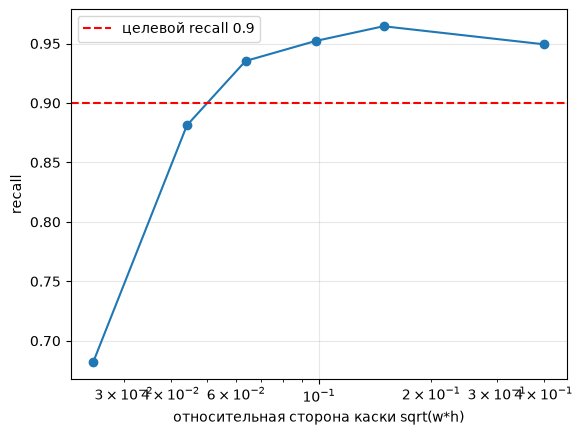

In [13]:
import matplotlib.pyplot as plt

centers, recalls, ns = [], [], []
for lo, hi in zip(borders, borders[1:]):
    subset = [hit for size, hit in rows if lo <= size < hi]
    if subset:
        centers.append((lo + hi) / 2)
        recalls.append(sum(subset) / len(subset))
        ns.append(len(subset))

plt.plot(centers, recalls, 'o-')
plt.axhline(0.9, ls='--', c='r', label='целевой recall 0.9')
plt.xscale('log')          # размеры распределены лог-нормально
plt.xlabel('относительная сторона каски sqrt(w*h)')
plt.ylabel('recall')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

ДЕЛАЕМ ВЫВОД, RECALL ПАДАЕТ ДЛЯ РАЗМЕРА КАСКИ В 4 ПРОЦЕНТА ОТ СТОРОНЫ КАДРА, ОТ 640x640 это примерно 19px